In [1]:
#Cell 1: Load and align
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)

preds = pd.read_csv("../data/processed/test_predictions.csv", index_col=0, parse_dates=True)
lstm = pd.read_csv("../data/processed/lstm_predictions.csv", index_col=0, parse_dates=True).iloc[:, 0]

common = preds.loc[lstm.index].copy()
common["lstm"] = lstm
common["ensemble"] = (common["lightgbm_v2"] + common["lstm"]) / 2

MODELS = ["naive_24", "naive_168", "lightgbm", "lightgbm_v2", "lstm", "ensemble"]
print(len(common), common.index.min(), "->", common.index.max())

5136 2018-01-01 00:00:00 -> 2018-08-02 23:00:00


In [2]:
#Cell 2: Final results table
def metrics(y_true, y_pred):
    e = y_true - y_pred
    return {"MAE": np.mean(np.abs(e)), "RMSE": np.sqrt(np.mean(e**2)),
            "MAPE_%": np.mean(np.abs(e / y_true)) * 100}

table = pd.DataFrame({m: metrics(common["actual"], common[m]) for m in MODELS}).T
table = table.sort_values("MAE").round(2)
print(table)
table.to_csv("../reports/results.csv")

                 MAE     RMSE  MAPE_%
ensemble     1466.78  2113.18    4.40
lightgbm_v2  1510.86  2180.70    4.52
lstm         1514.63  2144.81    4.59
lightgbm     2016.42  2700.44    6.24
naive_24     2530.64  3397.36    7.91
naive_168    3622.15  4948.33   11.11


In [3]:
#Cell 3: Is the difference significant?
def dm_test(a, b):
    """Diebold-Mariano style test on daily mean absolute errors (HAC standard errors)."""
    ea = (common["actual"] - common[a]).abs().resample("D").mean()
    eb = (common["actual"] - common[b]).abs().resample("D").mean()
    d = (ea - eb).dropna()
    fit = sm.OLS(d.values, np.ones(len(d))).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
    return d.mean(), fit.pvalues[0]

pairs = [("naive_24", "lightgbm_v2"), ("lightgbm", "lightgbm_v2"),
         ("lightgbm_v2", "lstm"), ("lightgbm_v2", "ensemble"), ("lstm", "ensemble")]
rows = []
for a, b in pairs:
    diff, p = dm_test(a, b)
    rows.append({"A": a, "B": b, "mean daily MAE A - B (MW)": round(diff, 1), "p-value": round(p, 4)})
dm_table = pd.DataFrame(rows)
print(dm_table)
dm_table.to_csv("../reports/dm_tests.csv", index=False)

             A            B  mean daily MAE A - B (MW)  p-value
0     naive_24  lightgbm_v2                     1019.8   0.0000
1     lightgbm  lightgbm_v2                      505.6   0.0000
2  lightgbm_v2         lstm                       -3.8   0.8999
3  lightgbm_v2     ensemble                       44.1   0.0112
4         lstm     ensemble                       47.8   0.0006


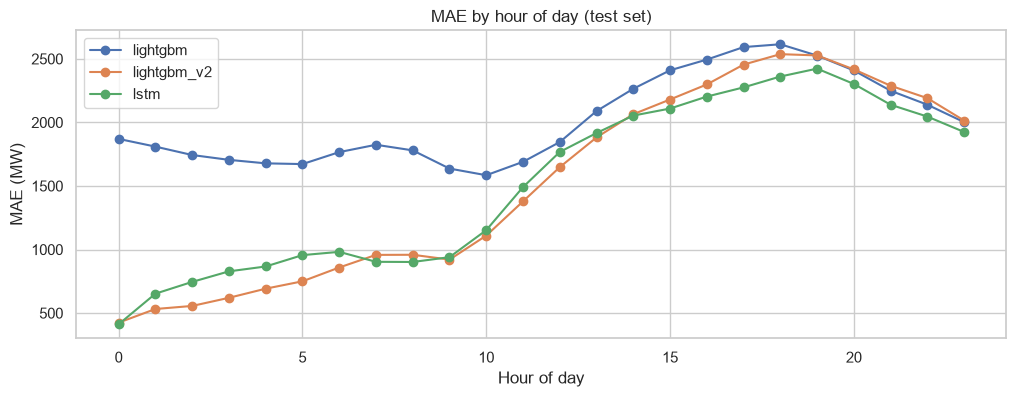

In [4]:
#Cell 4: Error by hour of day
err = pd.DataFrame({m: (common["actual"] - common[m]).abs()
                    for m in ["lightgbm", "lightgbm_v2", "lstm"]})
by_hour = err.groupby(err.index.hour).mean()

by_hour.plot(marker="o", figsize=(12, 4))
plt.title("MAE by hour of day (test set)")
plt.xlabel("Hour of day"); plt.ylabel("MAE (MW)")
plt.savefig("../reports/figures/09_error_by_hour.png", dpi=150)
plt.show()

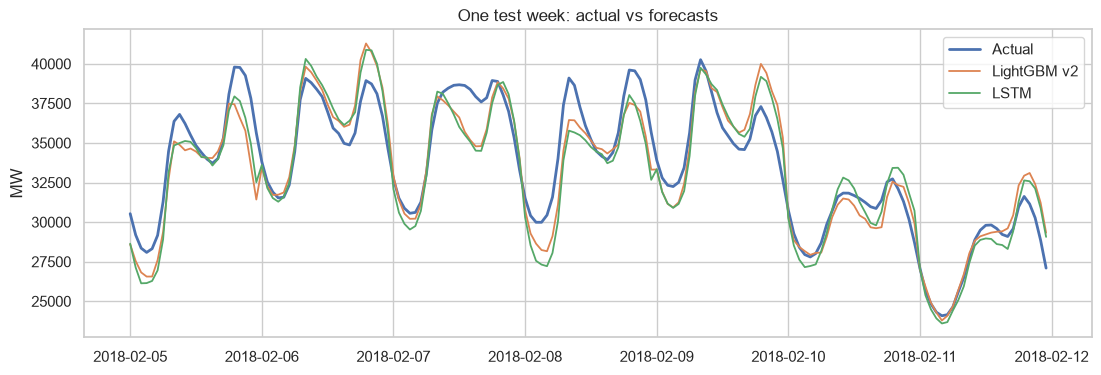

In [5]:
#Cell 5: One test week
week = common["2018-02-05":"2018-02-11"]
plt.figure(figsize=(13, 4))
plt.plot(week["actual"], label="Actual", lw=2)
plt.plot(week["lightgbm_v2"], label="LightGBM v2", lw=1.3)
plt.plot(week["lstm"], label="LSTM", lw=1.3)
plt.title("One test week: actual vs forecasts"); plt.ylabel("MW"); plt.legend()
plt.savefig("../reports/figures/10_final_week.png", dpi=150)
plt.show()

In [6]:
sarima = pd.read_csv("../data/processed/sarima_predictions.csv", index_col=0, parse_dates=True).iloc[:, 0]
sub = common.loc[sarima.index].copy()
sub["sarima"] = sarima

cols = ["naive_24", "sarima", "lightgbm_v2", "lstm", "ensemble"]
sarima_table = pd.DataFrame({m: metrics(sub["actual"], sub[m]) for m in cols}).T.sort_values("MAE").round(2)
print(f"First {sub.index.normalize().nunique()} test days:")
print(sarima_table)
sarima_table.to_csv("../reports/results_first30days.csv")

First 30 test days:
                 MAE     RMSE  MAPE_%
ensemble     1609.18  2115.80    4.45
lstm         1624.24  2078.52    4.50
lightgbm_v2  1746.02  2312.99    4.85
sarima       1813.08  2367.83    5.12
naive_24     2734.96  3359.40    7.97


In [7]:
common[["actual", "naive_24", "lightgbm_v2", "lstm", "ensemble"]].round(0).to_csv("../reports/demo_predictions.csv")